# 03 – How fast is the UK shifting to battery electric cars?

**Business question 1.** The shift is measured in two ways, because they tell different stories:

- **New car registrations (sales):** what people are buying today. This shows the *speed* of change.
- **Licensed cars (the fleet):** all cars on the road. This drives *charging demand*. Cars stay on the road for 10–15 years, so the fleet changes much more slowly than sales.

Method: simple shares, year-on-year changes and growth rates. No forecasting model is used.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROCESSED = "../data/processed/"
FIGURES = "../outputs/figures/"

# Chart style: light surface, quiet grid and axes, 2px lines
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": TEXT, "axes.labelcolor": TEXT_2,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})


def add_source(fig, text):
    fig.text(0.01, 0.01, text, fontsize=8, color=TEXT_2)

## 1. Sales: fuel mix of new cars, 2015–2025

In [2]:
registrations = pd.read_csv(PROCESSED + "new_car_registrations_uk.csv")
annual = registrations[registrations["period_type"] == "annual"].copy()
annual["year"] = annual["period"].astype(int)

fuel_groups = ["petrol", "diesel", "hybrid", "plugin_hybrid", "bev"]
shares = annual.set_index("year")[fuel_groups].div(annual.set_index("year")["total"], axis=0) * 100
shares.round(1)

,petrol,diesel,hybrid,plugin_hybrid,bev
year,,,,,
2015,49.0,48.3,1.7,0.7,0.4
2016,49.2,47.5,1.9,1.0,0.4
2017,53.4,41.9,2.8,1.4,0.5
2018,62.2,31.6,3.7,1.9,0.7
2019,65.6,26.5,4.7,1.5,1.6
2020,60.8,18.4,10.2,4.1,6.5
2021,54.4,11.6,15.7,6.8,11.4
2022,49.7,7.7,20.1,6.1,16.2
2023,46.2,6.5,23.8,7.2,16.1


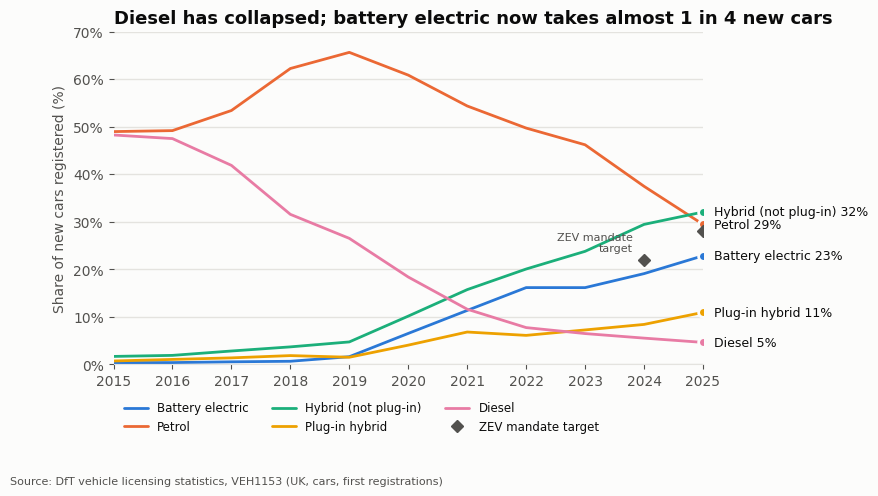

In [3]:
labels = {
    "bev": ("Battery electric", BLUE),
    "petrol": ("Petrol", ORANGE),
    "hybrid": ("Hybrid (not plug-in)", AQUA),
    "plugin_hybrid": ("Plug-in hybrid", YELLOW),
    "diesel": ("Diesel", MAGENTA),
}

fig, ax = plt.subplots(figsize=(9, 5.2))
for col, (label, color) in labels.items():
    ax.plot(shares.index, shares[col], color=color, label=label)
    ax.plot(shares.index[-1], shares[col].iloc[-1], "o", color=color, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{label} {shares[col].iloc[-1]:.0f}%", (shares.index[-1], shares[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT)

# ZEV mandate: minimum share of zero emission new cars, 2024 and 2025
ax.plot([2024, 2025], [22, 28], "D", color=TEXT_2, markersize=6, label="ZEV mandate target")
ax.annotate("ZEV mandate\ntarget", (2024, 22), xytext=(-8, 6), textcoords="offset points",
            ha="right", fontsize=8, color=TEXT_2)

ax.set_title("Diesel has collapsed; battery electric now takes almost 1 in 4 new cars")
ax.set_ylabel("Share of new cars registered (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 70)
ax.set_xlim(2015, 2025)
ax.set_xticks(range(2015, 2026))
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3, frameon=False, fontsize=8.5)
plt.subplots_adjust(right=0.78, bottom=0.24)
add_source(fig, "Source: DfT vehicle licensing statistics, VEH1153 (UK, cars, first registrations)")
fig.savefig(FIGURES + "01_new_car_fuel_mix.png", dpi=200)
plt.show()

**How to read this chart:** each line is one fuel type's share of all new cars registered in that year. The lines in each year add up to about 100%. Grey diamonds are the government's ZEV mandate targets.

**What it shows**
- **Diesel collapsed**, from 48% of new cars in 2015 to under 5% in 2025.
- **Battery electric rose from 0.4% to 23%.** The big jump came in 2020–2021, and growth has continued every year since, apart from a pause in 2023.
- **Non-plug-in hybrids are now the largest group (32%).** Many buyers leaving petrol and diesel choose a hybrid, not a full EV.
- **2025 BEV share (23%) is below the 28% ZEV mandate target.** The mandate lets manufacturers meet part of the target through flexibilities (for example credit trading and borrowing), so this does not by itself mean they failed it. It does show that demand is behind the policy path.

## 2. Sales vs fleet: battery electric share, quarterly

In [4]:
quarterly = registrations[registrations["period_type"] == "quarterly"].copy()
quarterly["quarter_end"] = pd.PeriodIndex(quarterly["period"].str.replace(" ", ""), freq="Q").end_time
quarterly["bev_share_sales"] = quarterly["bev"] / quarterly["total"] * 100

vehicles = pd.read_csv(PROCESSED + "vehicles_by_la.csv", parse_dates=["quarter_end"])
# Fleet = all licensed cars, summed over local authorities
fleet = vehicles[vehicles["body_type"] == "Cars"].groupby(["quarter", "quarter_end"], as_index=False)[["all_vehicles", "bev"]].sum()
fleet["bev_share_fleet"] = fleet["bev"] / fleet["all_vehicles"] * 100

start = "2019-01-01"
sales_q = quarterly[quarterly["quarter_end"] >= start]
fleet_q = fleet[fleet["quarter_end"] >= start]

fleet_q[["quarter", "all_vehicles", "bev", "bev_share_fleet"]].tail(9).round(2)

,quarter,all_vehicles,bev,bev_share_fleet
58,2024 Q2,33255189.0,1071723.0,3.22
59,2024 Q3,33336216.0,1169704.0,3.51
60,2024 Q4,33283381.0,1263479.0,3.80
61,2025 Q1,33460420.0,1376426.0,4.11
62,2025 Q2,33662326.0,1478272.0,4.39
63,2025 Q3,33797816.0,1599368.0,4.73
64,2025 Q4,33786235.0,1701862.0,5.04
65,2026 Q1,33928807.0,1827468.0,5.39
66,2026 Q2,34196860.0,1977019.0,5.78


In [5]:
# Same quarter, one year apart: removes seasonal effects
sales_q.set_index("period")["bev_share_sales"].loc[["2024 Q1", "2025 Q1", "2026 Q1", "2024 Q2", "2025 Q2", "2026 Q2"]].round(1)

period
2024 Q1    15.1
2025 Q1    20.3
2026 Q1    21.8
2024 Q2    17.5
2025 Q2    22.2
2026 Q2    27.3
Name: bev_share_sales, dtype: float64

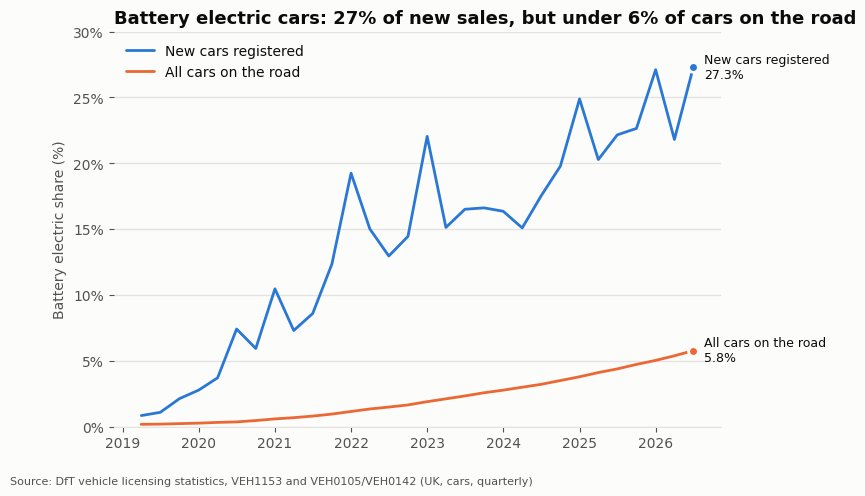

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.2))
series = [
    (sales_q, "bev_share_sales", "New cars registered", BLUE),
    (fleet_q, "bev_share_fleet", "All cars on the road", ORANGE),
]
for df, col, label, color in series:
    ax.plot(df["quarter_end"], df[col], color=color, label=label)
    last = df.iloc[-1]
    ax.plot(last["quarter_end"], last[col], "o", color=color, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{label}\n{last[col]:.1f}%", (last["quarter_end"], last[col]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT)

ax.set_title("Battery electric cars: 27% of new sales, but under 6% of cars on the road")
ax.set_ylabel("Battery electric share (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 30)
ax.legend(loc="upper left", frameon=False)
plt.subplots_adjust(right=0.8, bottom=0.12)
add_source(fig, "Source: DfT vehicle licensing statistics, VEH1153 and VEH0105/VEH0142 (UK, cars, quarterly)")
fig.savefig(FIGURES + "02_bev_share_sales_vs_fleet.png", dpi=200)
plt.show()

**How to read this chart:** the blue line is the share of *new* cars that are battery electric in each quarter. The orange line is the share of *all* licensed cars that are battery electric at the end of each quarter.

**What it shows**
- **Sales are far ahead of the fleet.** In 2026 Q2, 27% of new cars were battery electric, but only 5.8% of cars on the road (about 2.0 million of 34.2 million).
- **The fleet share is rising steadily**, from 1.5% in mid-2022 to 5.8% in mid-2026. It added 1.4 percentage points in the last year alone.
- The blue line moves up and down from quarter to quarter. Fleet and private buyers buy at different times of year (the UK has new number plates in March and September). Comparing the **same quarter year-on-year** removes this effect: 2026 Q1 was 21.8% (vs 20.3% in 2025 Q1), and 2026 Q2 was 27.3% (vs 22.2% in 2025 Q2). **Growth is speeding up again in 2026.**

**Why it matters:** even if sales stopped growing today, every quarter would still add more EVs to the fleet than it removes. Demand for charging will keep rising for years.

## 3. Battery electric cars on the road

In [7]:
fleet_from_2014 = fleet[fleet["quarter"] >= "2014 Q3"]

latest = fleet.set_index("quarter").loc["2026 Q2", "bev"]
year_ago = fleet.set_index("quarter").loc["2025 Q2", "bev"]
four_years_ago = fleet.set_index("quarter").loc["2022 Q2", "bev"]

# Average annual growth over four years (compound annual growth rate)
cagr = (latest / four_years_ago) ** (1 / 4) - 1

print(f"Battery electric cars, 2026 Q2:     {latest:,.0f}")
print(f"Growth in the last year:            {latest / year_ago - 1:.0%}")
print(f"Times larger than four years ago:   {latest / four_years_ago:.1f}x")
print(f"Average yearly growth, 2022-2026:   {cagr:.0%}")

Battery electric cars, 2026 Q2:     1,977,019
Growth in the last year:            34%
Times larger than four years ago:   4.1x
Average yearly growth, 2022-2026:   42%


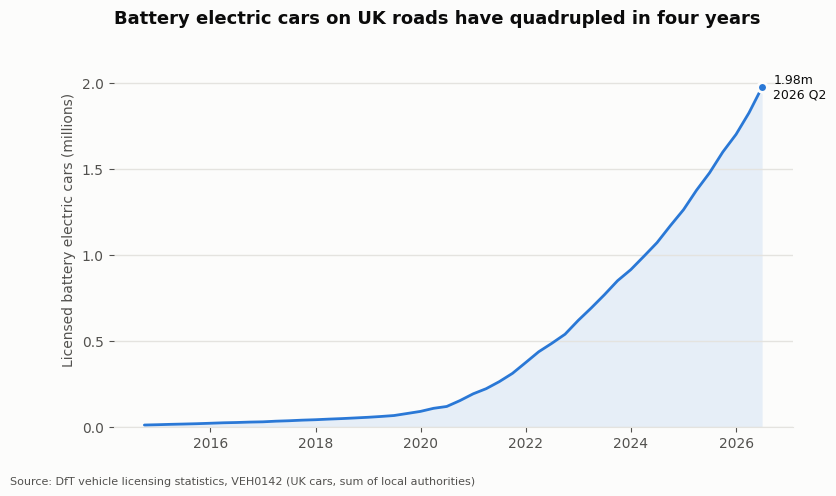

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(fleet_from_2014["quarter_end"], fleet_from_2014["bev"] / 1e6, color=BLUE)
ax.fill_between(fleet_from_2014["quarter_end"], fleet_from_2014["bev"] / 1e6, color=BLUE, alpha=0.1, linewidth=0)
last = fleet_from_2014.iloc[-1]
ax.plot(last["quarter_end"], last["bev"] / 1e6, "o", color=BLUE, markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"{last['bev'] / 1e6:.2f}m\n2026 Q2", (last["quarter_end"], last["bev"] / 1e6),
            xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT)

ax.set_title("Battery electric cars on UK roads have quadrupled in four years")
ax.set_ylabel("Licensed battery electric cars (millions)")
ax.set_ylim(0, 2.3)
plt.subplots_adjust(right=0.88, bottom=0.12)
add_source(fig, "Source: DfT vehicle licensing statistics, VEH0142 (UK cars, sum of local authorities)")
fig.savefig(FIGURES + "03_bev_cars_on_road.png", dpi=200)
plt.show()

**How to read this chart:** the number of licensed battery electric cars at the end of each quarter, in millions.

**What it shows**
- About **2.0 million** battery electric cars were licensed in mid-2026 (1.98 million assigned to a local authority; the published UK total is 2.02 million).
- That is **4.1 times** the number four years earlier, an average growth of about **42% a year**. Growth in the last year was **34%**.
- The curve is still getting steeper: each year adds more cars than the year before.

## Answer to question 1

- **Sales are shifting fast.** Battery electric went from 0.4% of new cars in 2015 to 23% in 2025, and reached 27% in 2026 Q2. Diesel has almost disappeared from new sales.
- **But the shift is slower than policy targets.** 2025 was below the 28% ZEV mandate target, and non-plug-in hybrids are absorbing much of the move away from petrol.
- **The fleet lags sales by years.** Only 5.8% of cars on the road are battery electric, but that is about 2 million cars, growing about a third every year.

**Implication for charging:** the number of EVs that need charging is growing about 34% a year and will keep growing even if sales flatten. The next question is whether public charging is keeping pace, and where it is not.